# 02 · Baseline models on the application table only

Four models, **identical 5-fold stratified CV**, no hyper-parameter tuning, only the main table.
The history tables (bureau, previous applications, instalments …) are added in a later notebook so their
contribution can be measured separately.

| Model | Missing values | Categories | Why it is here |
|---|---|---|---|
| LogReg (median) | filled with the training-fold median | one-hot | linear baseline; H2 control |
| LogReg (median + missing flags) | median + one 0/1 "was missing" column per feature | one-hot | H2: is missingness signal? |
| Random Forest | native NaN support | one-hot | averaging of deep trees; H3 calibration |
| LightGBM | native | native | boosted trees; usually strongest on tabular data |

Minimal feature engineering shared by all models (from the EDA): `DAYS_EMPLOYED` sentinel → `NaN`
+ `IS_PENSIONER` flag, `CREDIT_TO_INCOME`, `ANNUITY_TO_INCOME`.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load, ROOT
from src.features import application_features
from src.models import MODELS
from src.cv import run_cv, N_FOLDS
from src.viz import set_style, save, BLUE, INK_2, GRID, SURFACE

set_style()
PROC = ROOT / "data" / "processed"
SUB = ROOT / "submissions"
PROC.mkdir(parents=True, exist_ok=True)
SUB.mkdir(parents=True, exist_ok=True)

In [2]:
train = load("application_train")
X, y = application_features(train), train["TARGET"]
print(f"X: {X.shape[0]:,} rows × {X.shape[1]} features "
      f"({X.select_dtypes('number').shape[1]} numeric, {X.select_dtypes('category').shape[1]} categorical)")

X: 307,511 rows × 123 features (107 numeric, 16 categorical)


## Cross-validation
For every model: train on 4 folds, predict the 5th, repeat 5 times. The predictions made on the held-out fold
are collected into **out-of-fold (OOF)** predictions — one honest prediction per training client — which the
next notebook uses for calibration and error analysis.

In [3]:
fold_results, oof = [], {}
for name, make in MODELS.items():
    res, oof[name] = run_cv(make, X, y)
    res.insert(0, "model", name)
    fold_results.append(res)
    print(f"{name:<34} ROC-AUC {res['ROC-AUC'].mean():.4f} ± {res['ROC-AUC'].std():.4f}"
          f"   ({res['seconds'].sum():.0f}s)")
fold_results = pd.concat(fold_results, ignore_index=True)
pd.DataFrame(oof).assign(TARGET=y.values, SK_ID_CURR=train["SK_ID_CURR"].values) \
  .to_parquet(PROC / "oof_baseline.parquet")
fold_results.to_csv(PROC / "cv_baseline_folds.csv", index=False)

LogReg (median)                    ROC-AUC 0.7465 ± 0.0053   (30s)


LogReg (median + missing flags)    ROC-AUC 0.7486 ± 0.0053   (45s)


Random Forest                      ROC-AUC 0.7452 ± 0.0059   (200s)


LightGBM                           ROC-AUC 0.7585 ± 0.0052   (37s)


## Results
Mean over 5 folds; ± is the standard deviation across folds (how much the score moves with the split).

In [4]:
agg = fold_results.groupby("model", sort=False)[["ROC-AUC", "PR-AUC", "Brier", "LogLoss", "seconds"]]
table = agg.mean()
for m in ["ROC-AUC", "PR-AUC"]:
    table[m + " ±"] = fold_results.groupby("model", sort=False)[m].std()
table = table[["ROC-AUC", "ROC-AUC ±", "PR-AUC", "PR-AUC ±", "Brier", "LogLoss", "seconds"]]
table.style.format({"ROC-AUC": "{:.4f}", "ROC-AUC ±": "±{:.4f}", "PR-AUC": "{:.4f}", "PR-AUC ±": "±{:.4f}",
                    "Brier": "{:.4f}", "LogLoss": "{:.4f}", "seconds": "{:.0f}"})

,ROC-AUC,ROC-AUC ±,PR-AUC,PR-AUC ±,Brier,LogLoss,seconds
model,,,,,,,
LogReg (median),0.7465,±0.0053,0.2227,±0.0065,0.0687,0.2499,6
LogReg (median + missing flags),0.7486,±0.0053,0.2274,±0.0063,0.0685,0.2491,9
Random Forest,0.7452,±0.0059,0.2255,±0.0058,0.0693,0.2528,40
LightGBM,0.7585,±0.0052,0.2432,±0.0074,0.0679,0.2461,7


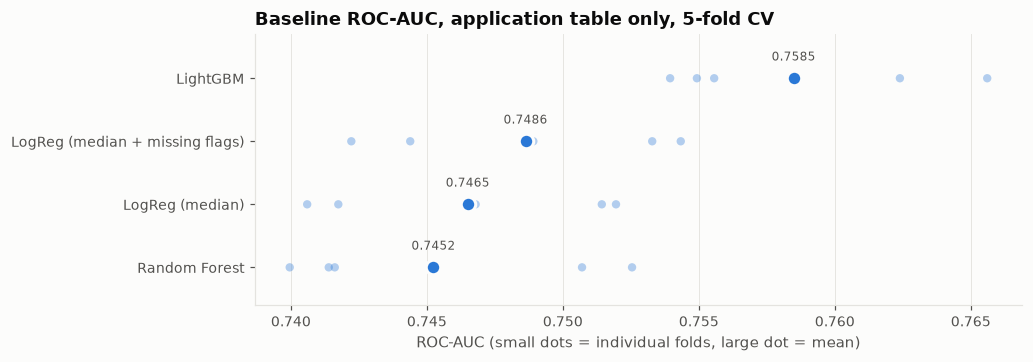

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.2))
order = table["ROC-AUC"].sort_values().index
for i, name in enumerate(order):
    s = fold_results.loc[fold_results.model == name, "ROC-AUC"]
    ax.scatter(s, [i] * len(s), color=BLUE, alpha=0.35, s=30, edgecolor="none")
    ax.scatter(s.mean(), i, color=BLUE, s=90, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.text(s.mean(), i + 0.28, f"{s.mean():.4f}", ha="center", fontsize=8, color=INK_2)
ax.set_yticks(range(len(order)), order)
ax.set_ylim(-0.6, len(order) - 0.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("ROC-AUC (small dots = individual folds, large dot = mean)")
ax.set_title("Baseline ROC-AUC, application table only, 5-fold CV")
save(fig, "baseline_auc")
plt.show()

## Kaggle submissions
Refit each model on the full training set and predict the test applications.

In [6]:
test = load("application_test")
X_test = application_features(test)
SLUG = {"LogReg (median)": "logreg", "LogReg (median + missing flags)": "logreg_flags",
        "Random Forest": "rf", "LightGBM": "lightgbm"}
for name, make in MODELS.items():
    model = make().fit(X, y)
    fname = SUB / f"baseline_{SLUG[name]}.csv"
    pd.DataFrame({"SK_ID_CURR": test["SK_ID_CURR"], "TARGET": model.predict_proba(X_test)[:, 1]}) \
      .to_csv(fname, index=False)
    print("written:", fname.name)

written: baseline_logreg.csv


written: baseline_logreg_flags.csv


written: baseline_rf.csv


written: baseline_lightgbm.csv
